# 0.1 — Team EDA: empty shelf space (gap detection)

**Task:** detect `gap` boxes (empty shelf space) on store-shelf photos. This is object detection, so the "target" of
an image is its set of gap boxes. We summarise it per image as `n_gaps`, `has_gap` and `empty_share` (fraction of the image
covered by gaps).

**Data:** `data/processed/retail-gap/`, the cleaned dataset (Roboflow gap photos + 57 fully stocked SKU-110K shelves,
grouped 70/15/15 split). The cleaning itself (label merge, duplicate removal, split) is in
`notebooks/eda/1.0-qp-eda-and-cleaning.ipynb`, and further checks are in `notebooks/eda/1.1-extra-eda-cleaned-data.ipynb`.
This notebook is the summary that covers the required EDA checklist.

| Section | Content |
|---|---|
| 1 | Data loading |
| 2 | Basic statistics |
| 3 | Visualizations |
| 4 | Train/val/test split strategy and verification |
| 5 | Leakage checks |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

from barcode.config import FIGURES_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR

DS = PROCESSED_DATA_DIR / "retail-gap"
FIG_DIR = FIGURES_DIR / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
SPLITS = ["train", "val", "test"]

%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data loading

Each row is one image. We read the YOLO label file of every image (`class cx cy w h`, all normalised) and join the
manifest written by the cleaning notebook (scene, duplicate group, original Roboflow split).

In [2]:
manifest = pd.read_csv(INTERIM_DATA_DIR / "retail-gap" / "manifest.csv").set_index("file")


def read_boxes(split, path):
    lab = DS / "labels" / split / path.with_suffix(".txt").name
    rows = [list(map(float, l.split())) for l in lab.read_text().splitlines() if l.strip()]
    return np.array(rows).reshape(-1, 5)  # class, cx, cy, w, h


def image_stats(path):
    im = Image.open(path)
    w, h = im.size
    small = im.convert("RGB").resize((160, 160))
    rgb = np.asarray(small, dtype=np.float32)
    grey = rgb.mean(axis=2)
    lap = grey[1:-1, 1:-1] * 4 - grey[:-2, 1:-1] - grey[2:, 1:-1] - grey[1:-1, :-2] - grey[1:-1, 2:]
    sat = np.asarray(small.convert("HSV"), dtype=np.float32)[..., 1].mean()
    return w, h, path.stat().st_size / (w * h), grey.mean(), grey.std(), sat, lap.var()


rows, box_rows = [], []
for split in SPLITS:
    for p in tqdm(sorted((DS / "images" / split).glob("*.jpg")), desc=split):
        b = read_boxes(split, p)
        w, h, bpp, bright, contrast, sat, sharp = image_stats(p)
        mask = np.zeros((104, 104), bool)  # union of boxes, so overlapping gaps count once
        for _, cx, cy, bw, bh in b:
            mask[max(int(round((cy - bh / 2) * 104)), 0):int(round((cy + bh / 2) * 104)),
                 max(int(round((cx - bw / 2) * 104)), 0):int(round((cx + bw / 2) * 104))] = True
        sku = p.name.startswith("sku110k_")
        rows.append(dict(file=p.name, split=split, source="full shelf (SKU-110K)" if sku else manifest.loc[p.name, "scene"],
                         width=w, height=h, bytes_per_px=bpp, brightness=bright, contrast=contrast, saturation=sat,
                         sharpness=sharp, n_gaps=len(b), has_gap=int(len(b) > 0), empty_share=mask.mean(),
                         group=-1 if sku else manifest.loc[p.name, "group"],
                         copy_cluster=-1 if sku else manifest.loc[p.name, "copy_cluster"],
                         orig_split=None if sku else manifest.loc[p.name, "orig_split"]))
        box_rows += [dict(file=p.name, split=split, cls=int(c), cx=cx, cy=cy, w=bw, h=bh) for c, cx, cy, bw, bh in b]

df = pd.DataFrame(rows)
boxes = pd.DataFrame(box_rows)
boxes["area"], boxes["aspect"] = boxes["w"] * boxes["h"], boxes["w"] / boxes["h"]
df.head()

,file,split,source,width,height,bytes_per_px,brightness,contrast,saturation,sharpness,n_gaps,has_gap,empty_share,group,copy_cluster,orig_split
0,11-lowResFull_10_jpg.rf.4e091c2b35c6a80b63d10f...,train,lab,416,416,0.144716,153.427689,52.778637,33.076523,882.730103,13,1,0.113351,343,343,val
1,11-lowResFull_10_jpg.rf.7ed2b3529abeac97d0560a...,train,lab,416,416,0.120429,51.268387,51.010132,116.377731,638.292603,13,1,0.123428,343,343,train
2,11-lowResFull_10_jpg.rf.91587f5afbb73d6fb270cf...,train,lab,416,416,0.144716,153.427689,52.778637,33.076523,882.730103,13,1,0.113351,343,343,train
3,11-lowResFull_10_jpg.rf.cb21289de3d3db0e06fc24...,train,lab,416,416,0.120360,51.265194,51.011848,116.542191,637.625854,13,1,0.121024,343,343,train
4,11-lowResFull_10_jpg.rf.d9a8665b576bd54532e251...,train,lab,416,416,0.132385,113.180481,55.271587,47.866600,827.936462,13,1,0.118713,343,343,test


In [3]:
boxes.head()

,file,split,cls,cx,cy,w,h,area,aspect
0,11-lowResFull_10_jpg.rf.4e091c2b35c6a80b63d10f...,train,0,0.666466,0.124399,0.068510,0.109375,0.007493,0.626377
1,11-lowResFull_10_jpg.rf.4e091c2b35c6a80b63d10f...,train,0,0.281851,0.305889,0.078125,0.131010,0.010235,0.596329
2,11-lowResFull_10_jpg.rf.4e091c2b35c6a80b63d10f...,train,0,0.480168,0.298678,0.056490,0.121394,0.006858,0.465344
3,11-lowResFull_10_jpg.rf.4e091c2b35c6a80b63d10f...,train,0,0.663462,0.266226,0.125000,0.152644,0.019081,0.818899
4,11-lowResFull_10_jpg.rf.4e091c2b35c6a80b63d10f...,train,0,0.266827,0.445312,0.072115,0.121394,0.008754,0.594057


## 2. Basic statistics

In [4]:
print(f"images table: {df.shape[0]:,} rows x {df.shape[1]} columns   |   boxes table: {boxes.shape[0]:,} rows x {boxes.shape[1]} columns")
print("\ncolumns and data types")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()}))

images table: 3,585 rows x 16 columns   |   boxes table: 17,237 rows x 9 columns

columns and data types


,dtype,missing,unique
file,str,0,3585
split,str,0,3
source,str,0,3
width,int64,0,6
height,int64,0,3
bytes_per_px,float64,0,3199
brightness,float32,0,3488
contrast,float32,0,3489
saturation,float32,0,3486
sharpness,float32,0,3490


`orig_split` is empty for the 57 SKU-110K images because they were not part of the Roboflow export. Every other column
is complete. There are no missing label files: an image with no gaps has an empty label file, and the check below
confirms that every image has one. Unreadable images would have raised an error while loading.

In [5]:
assert boxes["cls"].nunique() == 1 and boxes["cls"].iloc[0] == 0, "expected a single class (0 = gap)"
for split in SPLITS:
    imgs = {p.stem for p in (DS / "images" / split).glob("*.jpg")}
    labs = {p.stem for p in (DS / "labels" / split).glob("*.txt")}
    assert imgs == labs, f"{split}: image and label files do not match"
print("OK: one class (gap); every image has a label file")

feature_cols = ["width", "height", "bytes_per_px", "brightness", "contrast", "saturation", "sharpness",
                "n_gaps", "empty_share"]
display(df[feature_cols].describe().T.round(3))
display(boxes[["cx", "cy", "w", "h", "area", "aspect"]].describe().T.round(3))

OK: one class (gap); every image has a label file


,count,mean,std,min,25%,50%,75%,max
width,3585.0,416.804,9.971,359.000,416.000,416.000,416.000,640.000
height,3585.0,419.428,27.344,416.000,416.000,416.000,416.000,640.000
bytes_per_px,3585.0,0.183,0.061,0.076,0.157,0.180,0.201,0.756
brightness,3585.0,92.865,34.562,22.152,63.363,91.635,119.014,232.602
contrast,3585.0,48.837,7.017,21.262,44.787,48.960,53.431,70.440
saturation,3585.0,88.650,37.861,6.265,58.705,84.917,117.127,191.370
sharpness,3585.0,1487.828,657.035,151.787,1053.629,1407.385,1844.093,6680.744
n_gaps,3585.0,4.808,4.561,0.000,2.000,4.000,6.000,31.000
empty_share,3585.0,0.153,0.106,0.000,0.072,0.129,0.215,0.628


,count,mean,std,min,25%,50%,75%,max
cx,17237.0,0.501,0.232,0.006,0.334,0.500,0.668,0.994
cy,17237.0,0.472,0.235,0.011,0.287,0.450,0.651,0.977
w,17237.0,0.146,0.135,0.010,0.053,0.103,0.191,0.994
h,17237.0,0.191,0.082,0.019,0.135,0.162,0.228,0.931
area,17237.0,0.032,0.041,0.001,0.008,0.018,0.039,0.476
aspect,17237.0,0.804,0.802,0.060,0.312,0.542,0.985,10.643


## 3. Visualizations

### 3.1 Class / target distribution

There is a single class, so the target distribution is what matters: how many images contain gaps and how many gaps each
image has. The "no gap" images are only the 57 fully stocked shelves, so the problem is heavily skewed towards images
that contain gaps.

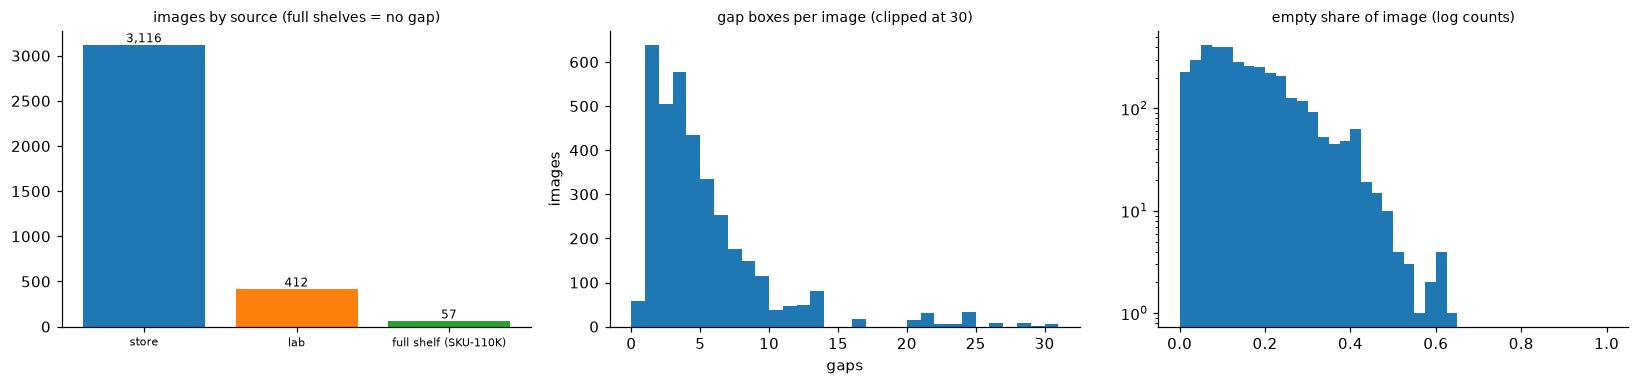

98.4% of images contain at least one gap; median gaps per image = 4


In [6]:
src_order = ["store", "lab", "full shelf (SKU-110K)"]
colors = {"store": "#1f77b4", "lab": "#ff7f0e", "full shelf (SKU-110K)": "#2ca02c"}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

counts = df.groupby("source")["has_gap"].agg(["sum", "count"]).reindex(src_order)
axes[0].bar(src_order, counts["count"], color=[colors[s] for s in src_order])
for i, (s, r) in enumerate(counts.iterrows()):
    axes[0].text(i, r["count"], f"{int(r['count']):,}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("images by source (full shelves = no gap)", fontsize=9)
axes[0].tick_params(axis="x", labelsize=7)

axes[1].hist(df["n_gaps"].clip(upper=30), bins=np.arange(0, 32), color="#1f77b4")
axes[1].set_title("gap boxes per image (clipped at 30)", fontsize=9)
axes[1].set_xlabel("gaps"); axes[1].set_ylabel("images")

axes[2].hist(df["empty_share"], bins=np.linspace(0, 1, 41), color="#1f77b4")
axes[2].set_yscale("log"); axes[2].set_title("empty share of image (log counts)", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "target_distribution.png", dpi=110)
plt.show()
print(f"{df['has_gap'].mean():.1%} of images contain at least one gap; median gaps per image = {df['n_gaps'].median():.0f}")

### 3.2 Feature distributions (histograms and box plots)

The "features" of an image are its pixels. We summarise them with simple statistics per image, and compare by source,
because the three sources look different.

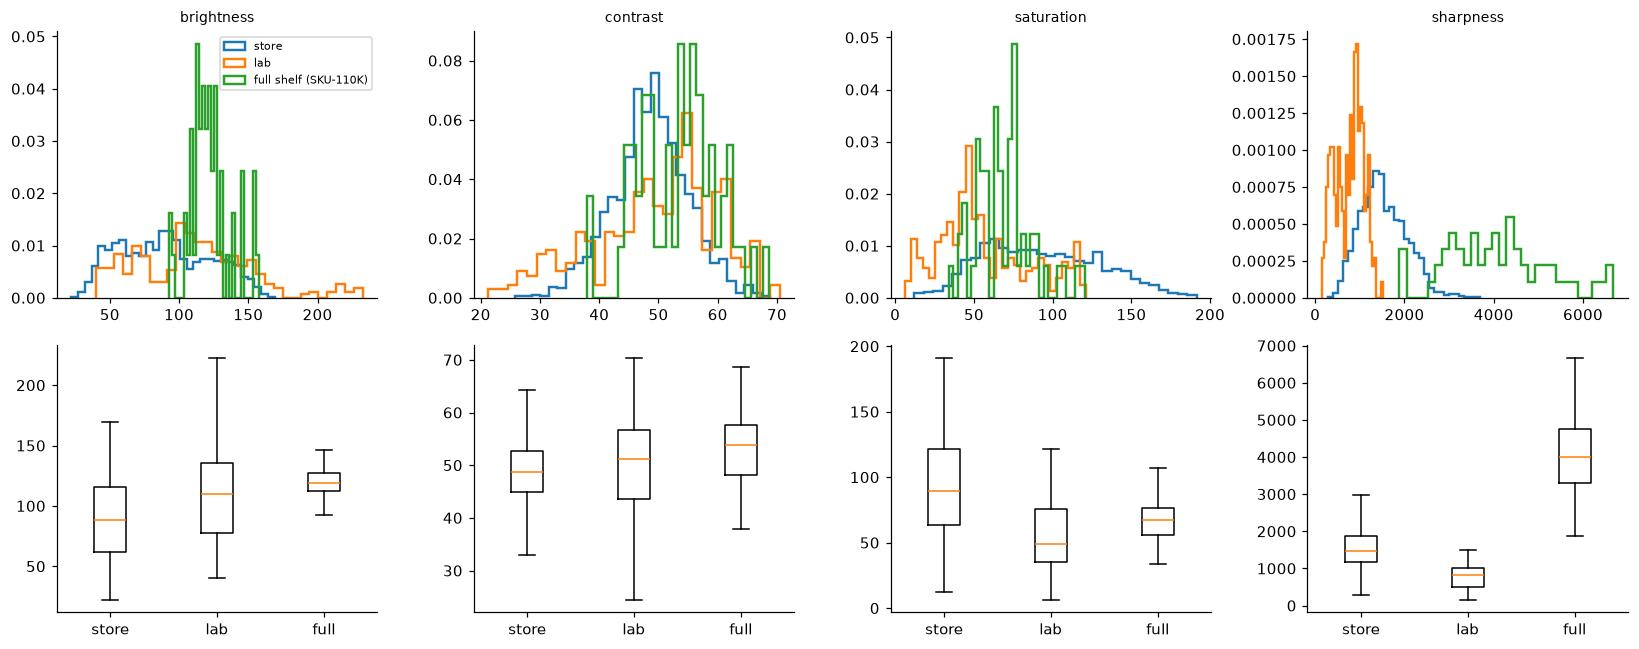

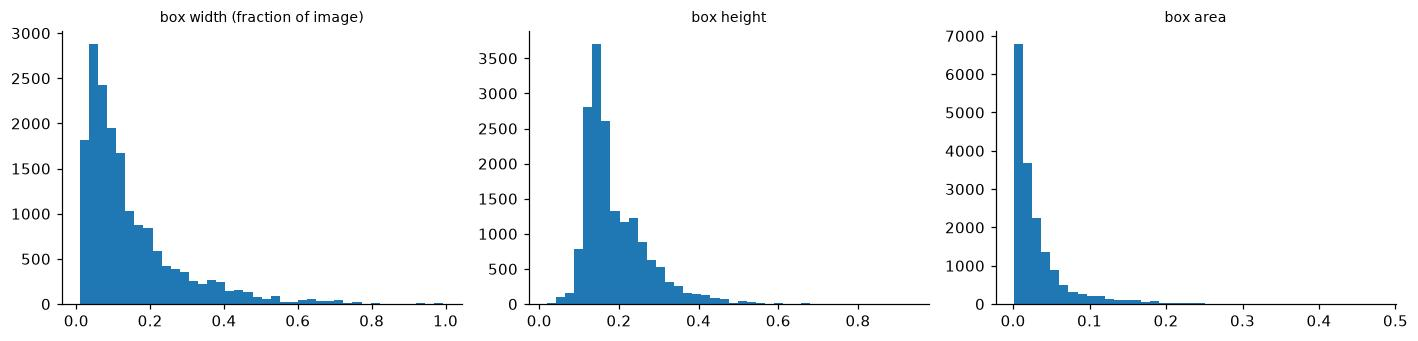

In [7]:
feats = ["brightness", "contrast", "saturation", "sharpness"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, f in enumerate(feats):
    for s in src_order:
        axes[0, j].hist(df.loc[df["source"] == s, f], bins=30, density=True, histtype="step", lw=1.6, color=colors[s], label=s)
    axes[0, j].set_title(f, fontsize=9)
    axes[1, j].boxplot([df.loc[df["source"] == s, f] for s in src_order], tick_labels=["store", "lab", "full"], showfliers=False)
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "feature_distributions.png", dpi=110)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, f, t in zip(axes, ["w", "h", "area"], ["box width (fraction of image)", "box height", "box area"]):
    ax.hist(boxes[f], bins=40, color="#1f77b4"); ax.set_title(t, fontsize=9)
fig.tight_layout()
plt.show()

### 3.3 Correlation heatmap

Correlations between the per-image features and the targets (`n_gaps`, `empty_share`). Spearman is used because
most of these variables are skewed.

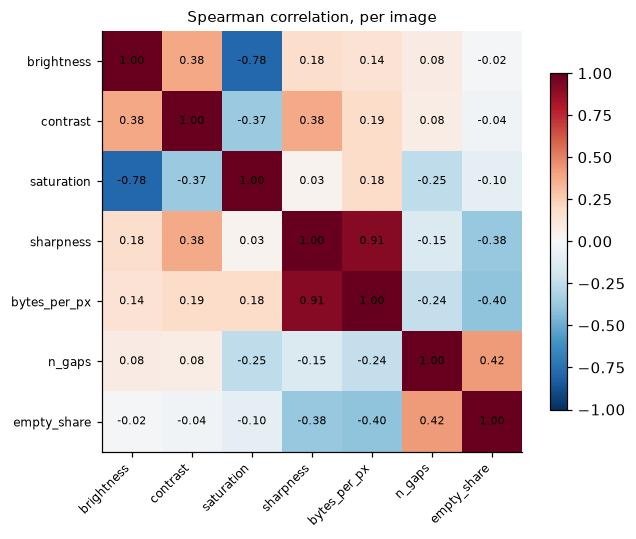

In [8]:
corr_cols = ["brightness", "contrast", "saturation", "sharpness", "bytes_per_px", "n_gaps", "empty_share"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, shrink=0.8)
ax.set_title("Spearman correlation, per image", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation_heatmap.png", dpi=110)
plt.show()

### 3.4 Key features vs. target

Each point is one image. We plot the image statistics against the amount of empty space.

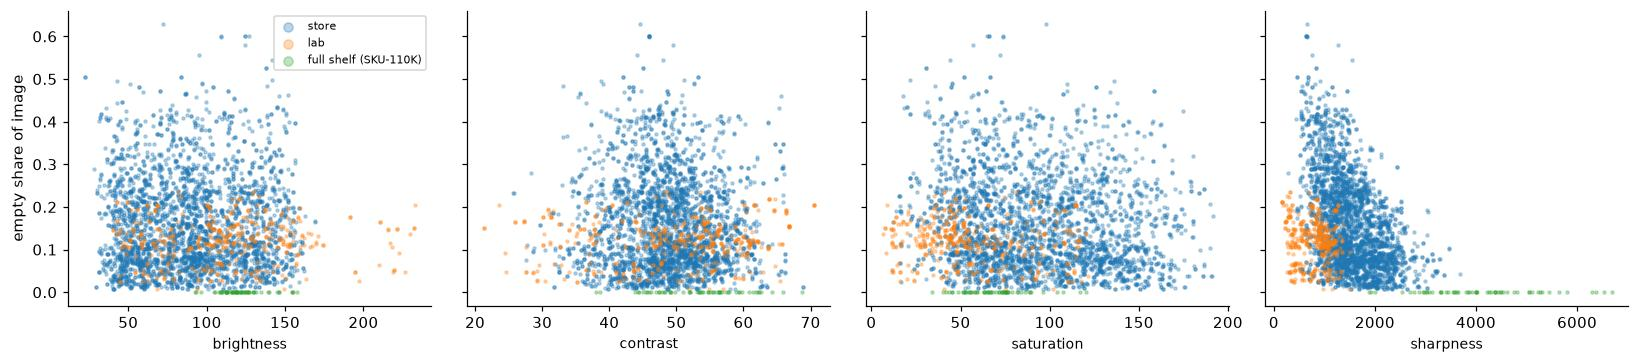

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, f in zip(axes, ["brightness", "contrast", "saturation", "sharpness"]):
    for s in src_order:
        d = df[df["source"] == s]
        ax.scatter(d[f], d["empty_share"], s=4, alpha=0.3, color=colors[s], label=s)
    ax.set_xlabel(f, fontsize=9)
axes[0].set_ylabel("empty share of image")
axes[0].legend(fontsize=7, markerscale=3)
fig.tight_layout()
fig.savefig(FIG_DIR / "features_vs_target.png", dpi=110)
plt.show()

### 3.5 Other exploratory plots: where gaps are, and what they look like

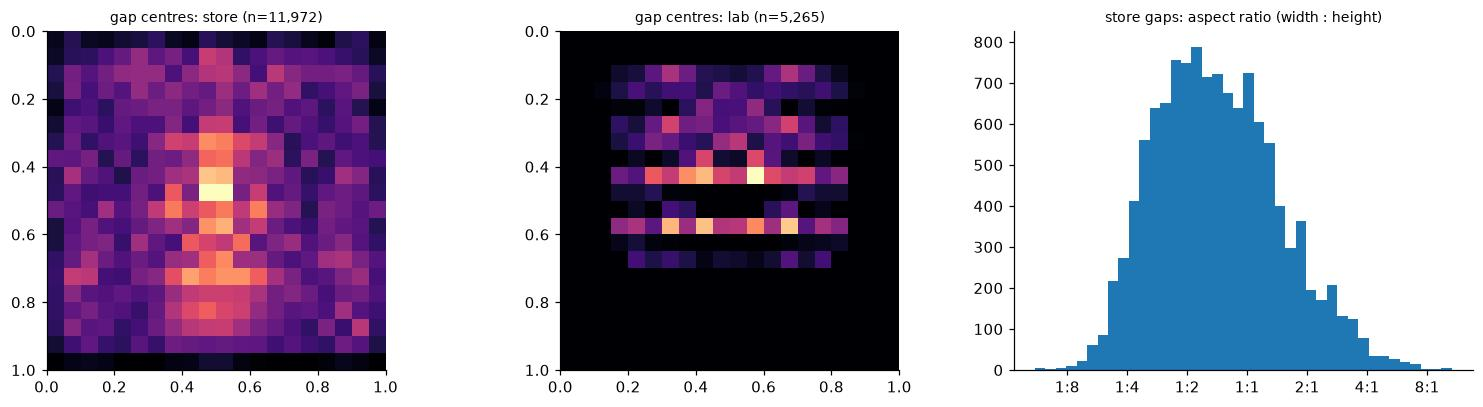

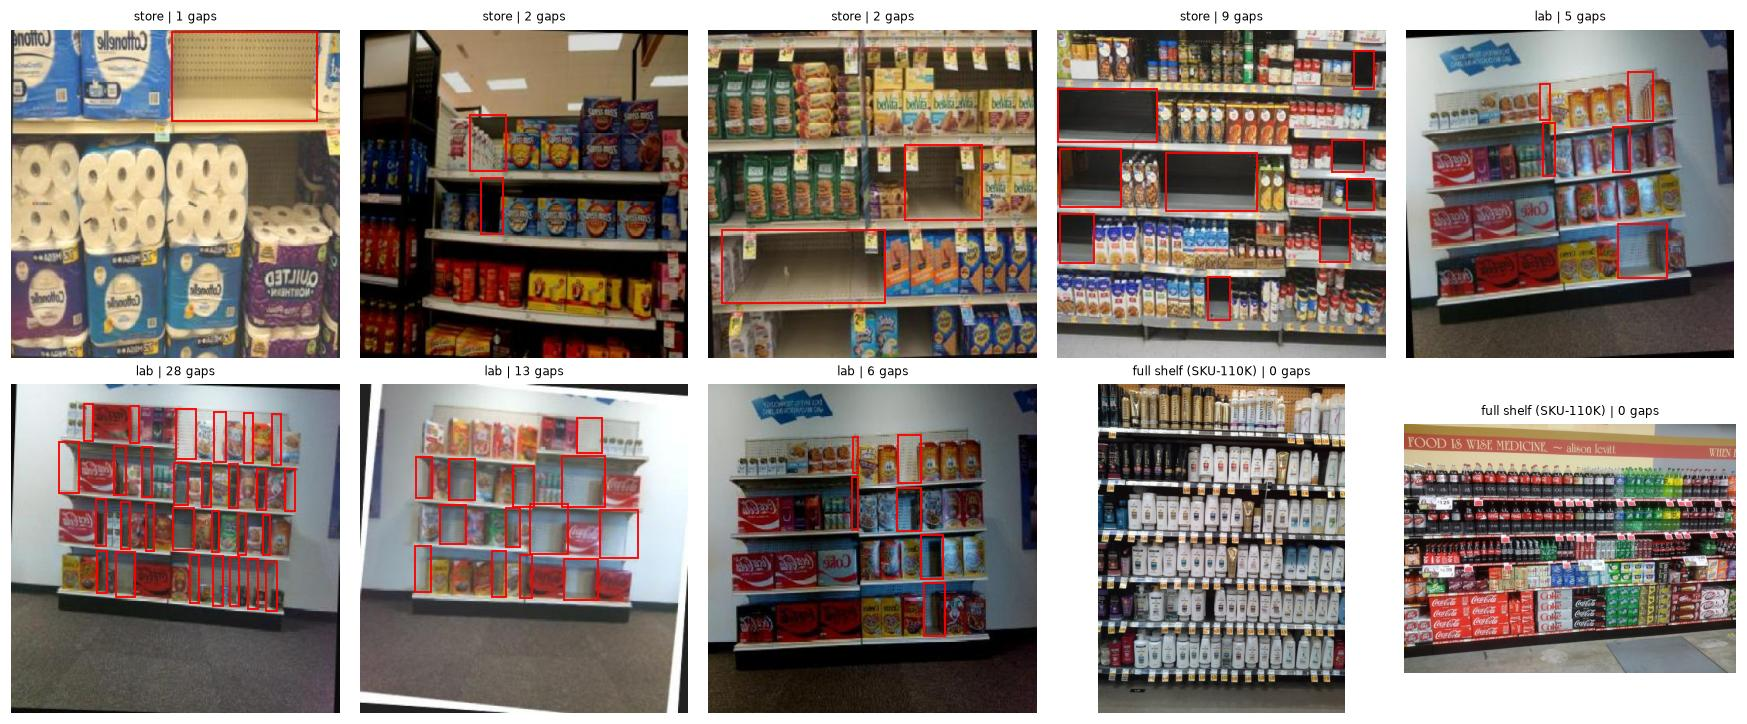

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, s in zip(axes[:2], ["store", "lab"]):
    sub = boxes[boxes["file"].isin(df.loc[df["source"] == s, "file"])]
    ax.hist2d(sub["cx"], sub["cy"], bins=20, range=[[0, 1], [0, 1]], cmap="magma")
    ax.invert_yaxis(); ax.set_aspect("equal"); ax.set_title(f"gap centres: {s} (n={len(sub):,})", fontsize=9)
st = boxes[boxes["file"].isin(df.loc[df["source"] == "store", "file"])]
axes[2].hist(np.log2(st["aspect"]), bins=40, color="#1f77b4")
axes[2].set_xticks([-3, -2, -1, 0, 1, 2, 3], ["1:8", "1:4", "1:2", "1:1", "2:1", "4:1", "8:1"])
axes[2].set_title("store gaps: aspect ratio (width : height)", fontsize=9)
fig.tight_layout()
plt.show()

# example images with their gap boxes
rng = np.random.default_rng(SEED)
pick = [rng.choice(df.index[df["source"] == s], 4, replace=False) for s in ["store", "lab"]]
pick = np.concatenate(pick + [df.index[df["source"] == "full shelf (SKU-110K)"][:2]])
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6))
for ax, i in zip(axes.ravel(), pick):
    r = df.loc[i]
    ax.imshow(Image.open(DS / "images" / r["split"] / r["file"]).convert("RGB"))
    W, H = Image.open(DS / "images" / r["split"] / r["file"]).size
    for _, b in boxes[boxes["file"] == r["file"]].iterrows():
        ax.add_patch(plt.Rectangle(((b["cx"] - b["w"] / 2) * W, (b["cy"] - b["h"] / 2) * H), b["w"] * W, b["h"] * H,
                                   fill=False, ec="red", lw=1.2))
    ax.set_title(f"{r['source']} | {r['n_gaps']} gaps", fontsize=8); ax.axis("off")
for ax in axes.ravel()[len(pick):]:
    ax.axis("off")
fig.tight_layout()
plt.show()

**Observations**
- Almost every image has gaps: only the 57 SKU-110K shelves have none. Most images have a few gaps (median 4), with a tail of
  lab images with 20+.
- Brightness and contrast are almost uncorrelated with the amount of empty space (|rho| < 0.1). Sharpness and JPEG bytes per
  pixel are moderately negative (about -0.4 with `empty_share`): empty shelf has less texture, and the full shelves
  (empty share 0) are much sharper. Most of the visual difference is between **sources** (store vs lab vs full shelf),
  not between gap and no-gap content.
- Gaps are mid-sized and appear throughout the shelf area. Lab-shelf gaps sit in a few fixed bands.
- `bytes_per_px` and image size separate the sources almost perfectly, which is a shortcut risk (see section 5 and
  notebook 1.1).

## 4. Train / val / test split

**Strategy.** The original Roboflow export (4,588 images) contained only about 1,080 unique photos, because most photos were
saved 3–6 times with augmentation, and the original val/test sets were largely copies of training photos (88%). So we
re-split:

1. Group images that are the same photo: same Roboflow filename stem, or a near-identical perceptual hash (including
   mirrored copies).
2. Assign **whole groups** to train / val / test, about 70 / 15 / 15 of the unique photos, stratified by scene.
3. Keep **one copy per photo** (copy cluster) in val and test, and all copies in train (as augmentation).
4. Add the 57 SKU-110K full shelves as background images, split 70/15/15.

Because train keeps every copy and val/test keep one per photo, train holds about 90% of the *images* even though the split is
70/15/15 of the *unique photos*.

The cell below verifies the split from the files and the manifest.

In [11]:
summary = df.groupby("split").agg(images=("file", "size"), gap_images=("has_gap", "sum"), gap_boxes=("n_gaps", "sum"),
                                  full_shelves=("source", lambda s: (s == "full shelf (SKU-110K)").sum())).reindex(SPLITS)
summary["share of images"] = (summary["images"] / summary["images"].sum()).round(3)
display(summary)
display(pd.crosstab(df["split"], df["source"]).reindex(index=SPLITS, columns=src_order))

# 1) every image is in exactly one split
assert df["file"].is_unique, "a file appears in more than one split"
# 2) no duplicate group is in more than one split (SKU images have group -1 and are skipped)
g = df[df["group"] != -1]
assert g.groupby("group")["split"].nunique().max() == 1, "a duplicate group spans several splits"
# 3) no Roboflow stem is in more than one split
stem = df["file"].str.replace(r"_jpg\.rf\..*", "", regex=True)
assert pd.concat([stem, df["split"]], axis=1).groupby("file")["split"].nunique().max() == 1
# 4) val/test keep exactly one copy per photo (a copy cluster = the same photo saved several times).
#    A near-duplicate *group* can hold several distinct but similar photos, e.g. consecutive shots, so it may appear more than once.
for s in ["val", "test"]:
    assert df[(df["split"] == s) & (df["copy_cluster"] != -1)]["copy_cluster"].is_unique, f"{s} has several copies of a photo"
c = df[df["copy_cluster"] != -1]
assert c.groupby("copy_cluster")["split"].nunique().max() == 1, "a copy cluster spans several splits"
# 5) the split uses the manifest's `split` column and only images flagged keep=True in val/test
m = manifest.reset_index()
kept_vt = set(m.loc[(m["split"].isin(["val", "test"])) & (m["keep"]), "file"])
assert set(df.loc[df["split"].isin(["val", "test"]) & (df["source"] != "full shelf (SKU-110K)"), "file"]) == kept_vt
print("OK: each image is in one split, no duplicate group or copy cluster crosses splits, val/test have one copy per photo")

,images,gap_images,gap_boxes,full_shelves,share of images
split,,,,,
train,3239,3199,15665,40,0.903
val,172,164,764,8,0.048
test,174,165,808,9,0.049


source,store,lab,full shelf (SKU-110K)
split,,,
train,2822,377,40
val,146,18,8
test,148,17,9


OK: each image is in one split, no duplicate group or copy cluster crosses splits, val/test have one copy per photo


## 5. Leakage checks

There are three ways information could leak here.

**(a) Features derived from the target.** The model input is only the image (pixels). The labels (gap boxes) are used
only as the target, and nothing is computed from them to build input features. The tile baselines add the tile's
position and nothing else. The per-image columns in this notebook that come from the labels (`n_gaps`, `empty_share`,
`has_gap`) are targets and are never used as inputs.

**(b) Leakage between splits (the same photo in train and val/test).** This was the project's big finding (88% of the
original val/test images had a copy in train). It is checked for the new split in section 4 and below.

**(c) Future information.** The images have no timestamps and no sequence, so there is no temporal leakage. Consecutive
shots of the same shelf are covered by (b), since they are matched by perceptual hash.

In [12]:
# (a) are any input features suspiciously tied to the target? Spearman with n_gaps and empty_share
inputs = ["width", "height", "bytes_per_px", "brightness", "contrast", "saturation", "sharpness"]
chk = pd.DataFrame({t: df[inputs].corrwith(df[t], method="spearman") for t in ["n_gaps", "empty_share"]}).round(3)
display(chk)
print("largest |correlation| with a target:", chk.abs().to_numpy().max().round(3),
      "(a feature derived from the target would be close to 1)")

# (b) how the original Roboflow split compared with the new one: copies across splits
orig = df[df["orig_split"].notna()].copy()
orig["stem"] = orig["file"].str.replace(r"_jpg\.rf\..*", "", regex=True)
new_split_per_group = orig.groupby("group")["split"].nunique()
orig_split_per_group = orig.groupby("group")["orig_split"].nunique()
print(f"photo groups spanning several splits: ORIGINAL split {(orig_split_per_group > 1).mean():.1%} "
      f"-> NEW split {(new_split_per_group > 1).mean():.1%}")

,n_gaps,empty_share
width,-0.142,-0.141
height,-0.218,-0.217
bytes_per_px,-0.240,-0.404
brightness,0.080,-0.018
contrast,0.077,-0.039
saturation,-0.253,-0.100
sharpness,-0.145,-0.382


largest |correlation| with a target: 0.404 (a feature derived from the target would be close to 1)
photo groups spanning several splits: ORIGINAL split 42.0% -> NEW split 0.0%


**Result.** No input feature is close to the target (largest rank correlation shown above), and no duplicate group spans
more than one split in the new dataset, compared with a large share in the original split.

**One remaining caution: the source shortcut.** This isn't target leakage in the strict sense, but it behaves like it:
image size and JPEG file statistics identify the 57 full shelves (SKU-110K) with AUC 1.0 (see notebook 1.1, section 2), so a
model could score "no gap" images by recognising the source instead of an intact shelf. Make the SKU-110K images
match the gap images (same size and JPEG settings) before trusting the full-shelf scores. The lab shelf (~12% of images)
also shows one scene from nearly the same position, so some overlap between splits remains by nature. Report the
store-only score as the headline number.